We'll expand the characterization of the baseline microbiome in this notebook to cover all our potential metrics and 

In [1]:
import itertools as it
import os
import warnings

import biom
import numpy as np
import pandas as pd
import scipy
import skbio
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.diversity.actions as q2_div
import qiime2.plugins.feature_table.actions as q2_feature_table
import qiime2.plugins.taxa.actions as q2_taxa

rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

%matplotlib inline

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
warnings.simplefilter(category=FutureWarning, action='ignore')

In [3]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
beta_metrics = ['jaccard', 'braycurtis', 
                'unweighted_unifrac', 'weighted_unifrac']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): c for i, c in enumerate(colors)}

# Data

In [4]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)

In [5]:
meta_bl = meta.loc[meta['timepoint'].isin([0, '0.0'])].copy()
meta_bl_q2 = Metadata(meta_bl)

In [6]:
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_dir = 'final-data/03.alpha-diveristy/'
alpha_q2 = {metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
            for metric in alpha_metrics}
alpha = pd.DataFrame({metric: art.view(pd.Series) for metric, art in alpha_q2.items()})
alpha_bl = alpha.loc[meta_bl.index].copy()
obs_feat = alpha_bl['observed_features']
obs_feat.mask(obs_feat - obs_feat.mean() > 2 * obs_feat.std(), inplace=True)
alpha_bl['z_obs_feat'] = \
    (alpha_bl['observed_features'] - obs_feat.mean()) / obs_feat.std()

In [7]:
beta_metrics = ['braycurtis', 'unweighted_unifrac', 'weighted_unifrac', 'jaccard']
beta_dm_q2 = {
    metric: Artifact.load(f'final-data/04.beta-diveristy/{metric}_1M_avg_dm.qza')
    for metric in beta_metrics
}
beta_dm_q2 = {
    metric: q2_div.filter_distance_matrix(dm_q2, metadata=meta_bl_q2).filtered_distance_matrix
    for metric, dm_q2 in beta_dm_q2.items()
}

In [8]:
beta_pc_q2 = {
    metric: q2_div.pcoa(dm_q2, number_of_dimensions=3).pcoa
    for metric, dm_q2 in beta_dm_q2.items()
}

In [9]:
beta_dm_q2['rpca'] = Artifact.load('final-data/05.rpca/baseline_rpca/distance-matrix.qza')
beta_dm_q2['phylo-rpca'] = \
    Artifact.load('final-data/05.rpca/baseline_phylo_rpca/distance-matrix.qza')

In [10]:
beta_pc_q2['rpca'] = Artifact.load('final-data/05.rpca/baseline_rpca/biplot.qza')
beta_pc_q2['phylo-rpca'] = \
    Artifact.load('final-data/05.rpca/baseline_phylo_rpca/biplot.qza')

We need to write the baseline files so we can run things through R in adonis

In [11]:
baseline_dir = 'final-data/06.baseline_compare'
os.makedirs(baseline_dir, exist_ok=True)
meta_bl.to_csv(f'{baseline_dir}/meta_baseline.tsv',
               sep='\t')
for metric, dm_q2 in beta_dm_q2.items():
    dm_q2.view(skbio.DistanceMatrix).write(f'{baseline_dir}/{metric}_baseline.tsv')

In [12]:
%%bash
Rscript scripts/baseline_adonis_force.r

In [13]:
taxa_adonis = pd.read_csv('final-data/06.baseline_compare/adonis_res.tsv',
                          sep='\t',
                          dtype=str)
taxa_adonis[['R2', 'p_value']] = taxa_adonis[['R2', 'p_value']].astype(float)
taxa_adonis['nperm'] = taxa_adonis['nperm'].astype(int)


In [14]:
taxa_adonis_f = taxa_adonis.loc[taxa_adonis['model'] == 'full'].copy()
taxa_adonis_f = \
    taxa_adonis_f.pivot(index='key_vars', 
                        columns='metric', 
                        values=['R2', 'p_value']
                       ).round(3)

taxa_adonis_f.sort_values([('R2', 'rpca')], ascending=False, inplace=True)
taxa_adonis_f

R2                                               \
metric   braycurtis jaccard phylo_rpca   rpca unweighted_unifrac   
key_vars                                                           
extract       0.087   0.131      0.100  0.108              0.148   
abx           0.065   0.060      0.078  0.074              0.057   
sex           0.008   0.014      0.011  0.011              0.017   
age           0.008   0.013      0.006  0.005              0.013   
diet          0.008   0.010      0.002  0.003              0.010   

                             p_value                            \
metric   weighted_unifrac braycurtis jaccard phylo_rpca   rpca   
key_vars                                                         
extract             0.039      0.416   0.001      0.245  0.189   
abx                 0.052      0.539   0.673      0.318  0.381   
sex                 0.022      0.813   0.256      0.507  0.480   
age                 0.007      0.821   0.426      0.719  0.786   
diet                0.006      0.802   0.691      0.931  0.903   

                                              
metric   unweighted_unifrac weighted_unifrac  
key_vars                                      
extract               0.001            0.980  
abx                   0.642            0.773  
sex                   0.136            0.229  
age                   0.296            0.678  
diet                  0.653            0.732

In [15]:
abrev = {'braycurtis': 'bc',
         'unweighted_unifrac': 'uu',
         'weighted_unifrac': 'wu',
         'jaccard': 'jc',
         'rpca': 'rpc',
         'phylo-rpca': 'ppc',
          }
coords = [meta_bl]
coords.extend(
    [pc.view(skbio.OrdinationResults).samples.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()]
)
coords = pd.concat(axis=1, objs=coords)

perc_exp = pd.concat(axis=0, objs=[
    pc.view(skbio.OrdinationResults).proportion_explained.add_prefix(abrev[metric])
    for metric, pc in beta_pc_q2.items()])

In [16]:
def _plot_adonis_bar(fig, metric):
    ax = fig.add_subplot(1,1,1)
    ax.barh(y=5-np.arange(5),
            left=0,
            width=taxa_adonis_f['R2'][metric],
            color='#525252',
           )
    ax.set_yticks(5-np.arange(5))
    ax.set_xlim(0, 0.175)
    ax.set_xticks(np.arange(0, 0.16, 0.05))

    p_vals = taxa_adonis_f['p_value'][metric]
    if (p_vals < 0.05).any():
        p_vals = np.floor(-np.log10(p_vals).mask(p_vals > 0.05, 0))
        p_vals = p_vals.astype(int).apply(lambda x: ''.join(['*'] * x))
        for i, (id_, p) in enumerate(p_vals.items()):
            ax.text(y=5 - i, 
                    x=taxa_adonis_f.loc[id_, "R2"][metric] + 0.1 * 0.175,
                    s=p,
                    rotation=90,
                    ha='center', 
                    va='center', 
                    size=8)
                    

    
    ax.set_yticklabels(['Extr', 'Abx', 'Sex', "Age", 'Diet'],
                       size=8)
    ax.yaxis.set_tick_params(left=False, labelleft=True, right=False, 
                             labelright=False, labelsize=7, length=0)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                             labeltop=False, labelsize=7, length=0)
    ax.xaxis.grid(True)
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:1.0%}'))
    ax.set_xlabel('Adonis $R^{2}$', size=7)
    sn.despine(ax=ax, left=True, right=True, top=True, bottom=False)

In [17]:
tick_in = dict(left=True, right=True, labelleft=False, labelright=False, labelsize=0, tickdir='in', length=2.5)
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
def _ord_plot(fig, pc0, pc1, hue, palette, data, perc_exp):
    """
    Makes an ordination plot
    """
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 4], width_ratios=[4, 1])
    axm = fig.add_subplot(gs[1, 0])
    ax0 = fig.add_subplot(gs[0, 0], sharex=axm, facecolor='None')
    ax1 = fig.add_subplot(gs[1, 1], sharey=axm, facecolor='None')

    scatter_kwargs = dict(edgecolor='None',
                          s=2,)
    box_kwargs = dict(linewidth=0.5,
                      fliersize=0.5)
    
    sn.scatterplot(ax=axm, x=pc0, y=pc1, data=data, hue=hue, palette=palette, 
                   **scatter_kwargs)
    sn.boxplot(ax=ax0, x=pc0, y=hue, palette=palette, data=data, **box_kwargs)
    sn.boxplot(ax=ax1, y=pc1, x=hue,  palette=palette, data=data, **box_kwargs)
    axm.get_legend().set_visible(False)
    axm.xaxis.set_major_locator(ticker.LinearLocator(5))
    axm.xaxis.set_tick_params(**tick_in)
    axm.yaxis.set_major_locator(ticker.LinearLocator(5))
    axm.yaxis.set_tick_params(**tick_in)
    axm.set_xlabel(f'PC 1 ({{{pc0}:1.1%}})'.format(**perc_exp), size=7)
    axm.set_ylabel(f'PC 2 ({{{pc1}:1.1%}})'.format(**perc_exp), size=7)
    
    for ax_ in [ax0.xaxis, ax0.yaxis, ax1.xaxis, ax1.yaxis]:
        ax_.set_tick_params(**hide_axes)
        ax_.get_label().set_visible(False)

    sn.despine(ax=ax0, left=True, right=True, top=True, bottom=True)
    sn.despine(ax=ax1, left=True, right=True, top=True, bottom=True)


In [18]:
extr_names = meta_bl['extraction_no'].unique()
extr_palette = {k: mpc.to_hex(c) for k, c in zip(*(extr_names, sn.color_palette(n_colors=len(extr_names))))}

In [19]:
met_order = [['jaccard', 'jc', 'Jaccard'],
             # ['unweighted_unifrac', 'uu', 'unweighted\nUniFrac'],
             ['rpca', 'rpc', 'rPCA'],
             ['phylo_rpca', 'ppc', 'phylo rPCA'],
             ['braycurtis', 'bc', 'Bray Curtis'],
             ['weighted_unifrac', 'wu', 'weighted\nUniFrac']
             ]

In [20]:
def _plot_baseline_pc(figt, figa, figc, metric, prefix, title):
    """
    Plots the ordination results
    """
    pc0 = f'{prefix}0'
    pc1 = f'{prefix}1'
    _ord_plot(figa, pc0, pc1, 'abx_code2', abx_colors, coords, perc_exp)
    # _ord_plot(figb, pc0, pc1, 'extraction_no', extr_palette, coords, perc_exp)
    _plot_adonis_bar(figc, metric)
    axt = figt.add_subplot(1,1,1, facecolor='None')
    axt.set_position((0, 0, 1, 1))
    axt.xaxis.set_tick_params(**hide_axes)
    axt.yaxis.set_tick_params(**hide_axes)
    axt.set_xlim(0, 1)
    axt.set_ylim(0, 1)
    axt.text(0.5, 0.5, title, ha='center', va='center', size=8)
    sn.despine(figt, left=True, right=True, top=True, bottom=True)

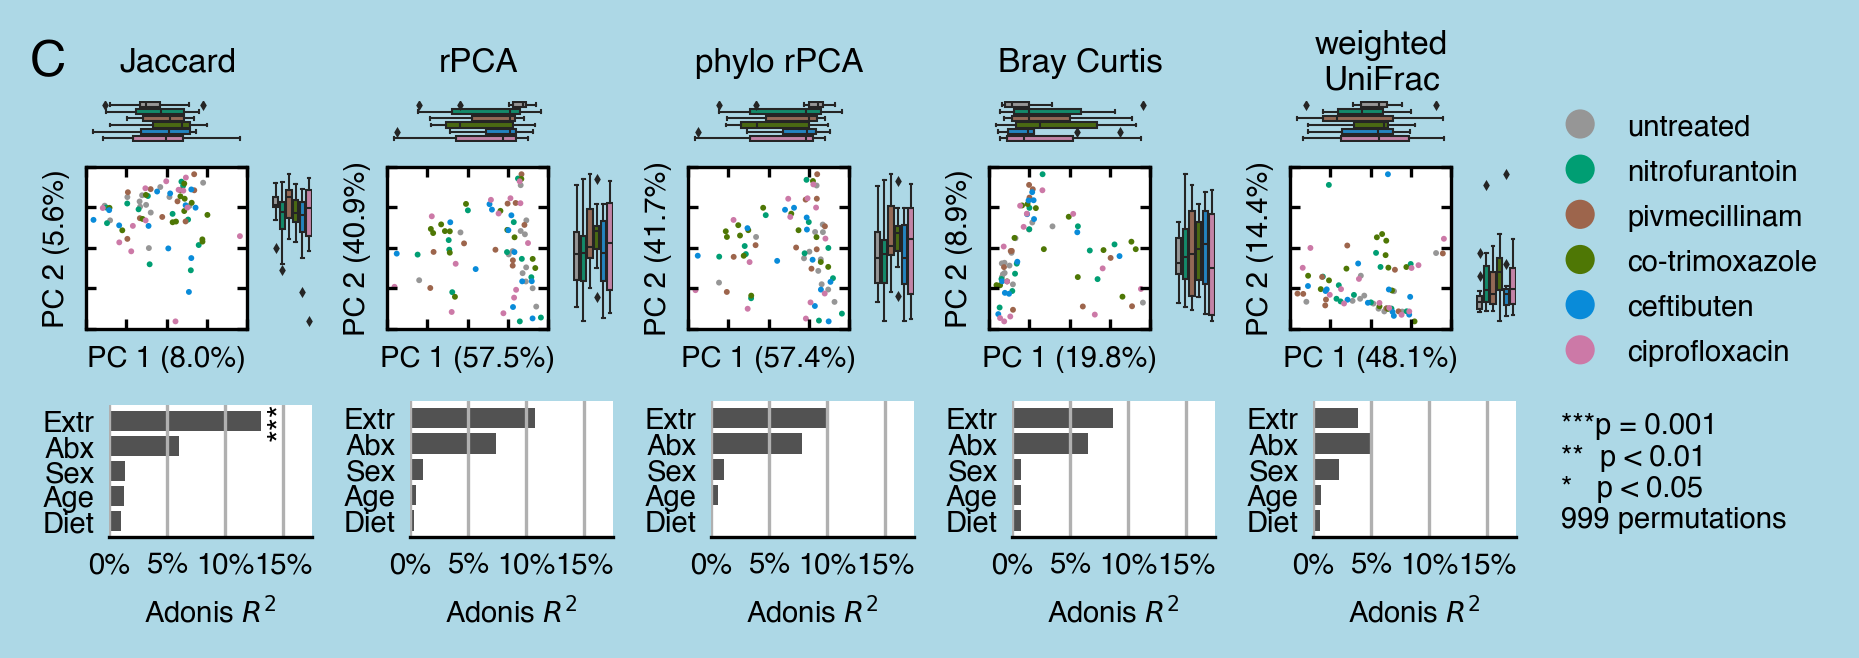

In [21]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(6, 2), facecolor='lightblue')
def _build_beta_panels(fig):
    """
    Convenience function to mak the beta figure easier
    """
    figs = fig.subfigures(3, 6, height_ratios=[0.15, 1, 0.85], facecolor='None')
    for fig_r, met_info in zip(*(figs.T, met_order)):
        _plot_baseline_pc(*fig_r, *met_info)
    axl = figs.T[-1][1].add_subplot(1,1,1, facecolor='None')
    axl.scatter(y=5 - np.arange(0, 6), 
                x=np.ones(6),
                c=colors,
                marker='o',
               )
    axl.set_ylim(-0.5, 5.5)
    axl.set_yticks(5 - np.arange(0, 6))
    axl.set_yticklabels(abx_order)
    axl.xaxis.set_tick_params(**hide_axes)
    axl.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=True, labelsize=7, length=0)
    sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)
    
    axa = figs.T[-1][2].add_subplot(1,1,1, facecolor='None')
    axa.set_xlim(0, 1)
    axa.set_ylim(0, 1)
    axa.text(s='***p = 0.001\n**  p < 0.01\n*   p < 0.05\n999 permutations',
             x=0.05, y=0.95, ha='left', va='top', size=7)
    axa.xaxis.set_tick_params(**hide_axes)
    axa.yaxis.set_tick_params(**hide_axes)
    sn.despine(ax=axa, left=True, right=True, top=True, bottom=True)
    figs[0][0].axes[0].text(figs[0][0].axes[0].get_xlim()[0],
                            np.mean(figs[0][0].axes[0].get_ylim()),
                            'C', size=12, ha='left', va='center')
    
_build_beta_panels(fig)

## Alpha Diversity

In [22]:
meta_a = pd.concat(axis=1, objs=[meta_bl, alpha_bl])
meta_a['age'] = meta_a['age'].astype(float)

In [23]:
def _anova_res_wrap(metric, fit_):
    """
    Pulls out the anova results for the baseline OLS
    """
    anova = sms.stats.anova_lm(fit_)
    anova['n_obs'] = fit_.nobs
    anova['p'] = anova['df'] + 1
    anova['r2'] = anova['sum_sq'] / anova['sum_sq'].sum()
    anova['metric'] = metric
    
    return anova

In [24]:
alpha_bl_fit = {
    metric: smf.ols(f'{metric} ~ abx_code2 + extraction_no + sex + age + vegetarian',
                    data=meta_a).fit()
    for metric in ['z_obs_feat', 'shannon', 'simpson']
}

In [25]:
alpha_anova_res = pd.concat(
    axis=0, 
    objs=[_anova_res_wrap(metric, fit_) 
          for metric, fit_ in alpha_bl_fit.items()]
)
alpha_anova_res.drop(['Residual'], inplace=True)
alpha_anova_res.set_index('metric', append=True, inplace=True)
alpha_anova_res.sort_values('r2', ascending=False, inplace=True)
alpha_anova_res

df    sum_sq   mean_sq         F    PR(>F)  n_obs  \
              metric                                                           
extraction_no z_obs_feat  6.0  7.918500  1.319750  1.283279  0.279250   73.0   
              simpson     6.0  0.020442  0.003407  0.776210  0.591812   74.0   
              shannon     6.0  2.316527  0.386088  0.663073  0.679598   74.0   
abx_code2     z_obs_feat  5.0  3.208536  0.641707  0.623974  0.682057   73.0   
              simpson     5.0  0.005709  0.001142  0.260150  0.932969   74.0   
vegetarian    z_obs_feat  1.0  1.038288  1.038288  1.009595  0.319174   73.0   
              shannon     1.0  0.520176  0.520176  0.893357  0.348424   74.0   
abx_code2     shannon     5.0  0.491590  0.098318  0.168853  0.973094   74.0   
sex           simpson     1.0  0.003376  0.003376  0.769183  0.384027   74.0   
vegetarian    simpson     1.0  0.002098  0.002098  0.478050  0.492019   74.0   
sex           shannon     1.0  0.182116  0.182116  0.312769  0.578103   74.0   
age           shannon     1.0  0.114642  0.114642  0.196888  0.658867   74.0   
              z_obs_feat  1.0  0.131300  0.131300  0.127671  0.722156   73.0   
              simpson     1.0  0.000362  0.000362  0.082570  0.774851   74.0   
sex           z_obs_feat  1.0  0.055010  0.055010  0.053490  0.817913   73.0   

                            p        r2  
              metric                     
extraction_no z_obs_feat  7.0  0.109979  
              simpson     7.0  0.070258  
              shannon     7.0  0.060995  
abx_code2     z_obs_feat  6.0  0.044563  
              simpson     6.0  0.019623  
vegetarian    z_obs_feat  2.0  0.014421  
              shannon     2.0  0.013696  
abx_code2     shannon     6.0  0.012944  
sex           simpson     2.0  0.011604  
vegetarian    simpson     2.0  0.007212  
sex           shannon     2.0  0.004795  
age           shannon     2.0  0.003019  
              z_obs_feat  2.0  0.001824  
              simpson     2.0  0.001246  
sex           z_obs_feat  2.0  0.000764

(-0.75, 5.75)

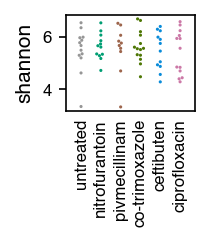

In [26]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 1.5))
gs = fig.add_gridspec(1, 3)
ax0 = fig.add_subplot(gs[0])
ax0.xaxis.set_tick_params(bottom=False, 
                          labelbottom=True, 
                          labelsize=8,
                          top=False, 
                          labeltop=False, 
                          length=0)
ax0.yaxis.set_tick_params(left=True, labelleft=True, 
                          right=False, labelright=False, 
                          labelsize=8)
sn.swarmplot(ax=ax0, 
           x='abx_code2', 
           y='shannon', 
           data=meta_a,
           order=['0', '1', '2', '3', '4', '5'],
           palette=abx_colors,
            s=1.5,
           )
ax0.set_xticks(np.arange(6))
ax0.set_xticklabels(abx_order, rotation=90)
ax0.xaxis.get_label().set_visible(False)

ax0.set_xlim(-0.75, 5.75)

In [27]:
var_order = ['extraction_no', 'abx_code2', 'vegetarian', 'age', 'sex']

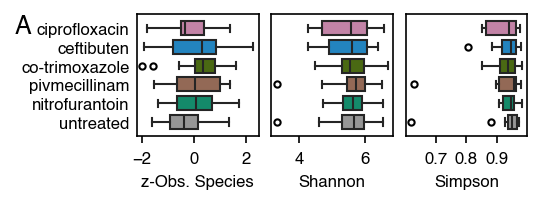

In [28]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3.5, 1.25))
def _plot_alpha_boxplot(fig):
    """
    A helper function to wrap panel plotting
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax)
        sn.boxplot(ax=ax, 
                   orient='h',
                   x=metric, 
                   y='abx_code2', 
                   data=meta_a,
                   order=['0', '1', '2', '3', '4', '5'],
                   palette=abx_colors,
                   width=0.75,
                   linewidth=1,
                   flierprops=dict(markersize=3, 
                                   markerfacecolor='None', 
                                   markeredgecolor='k',
                                   marker='o')
                   )
        ax.set_yticks(np.arange(6))
        ax.set_yticklabels(abx_order)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, length=0, labelsize=8)
        ax.yaxis.get_label().set_visible(False)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, labelsize=8)
        ax.set_ylim(-0.75, 5.75)
    fig.axes[0].set_xlabel('z-Obs. Species', size=8)
    fig.axes[1].set_xlabel('Shannon', size=8)
    fig.axes[2].set_xlabel('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 1,
                     fig.axes[0].get_ylim()[1],
                     'A',
                     size=12, ha='left', va='top')
_plot_alpha_boxplot(fig)

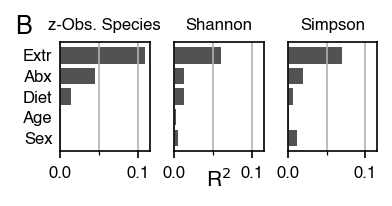

In [29]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(2.5, 1.25))
def _plot_r2_alpha(fig):
    """
    A wrapper function for alpha diveristy correlations?
    """
    gs = fig.add_gridspec(1, 3)
    for i, metric in enumerate(['z_obs_feat', 'shannon', 'simpson']):
        if i == 0:
            ax = fig.add_subplot(gs[i])
        else:
            ax = fig.add_subplot(gs[i], sharey=ax, sharex=ax)
        ax.yaxis.set_tick_params(left=False, labelleft=(i == 0), right=False, 
                                 labelright=False, labelsize=8, length=0)
        ax.xaxis.set_tick_params(bottom=True, labelbottom=True, top=False, 
                                 labeltop=False, labelsize=8)
        ax.barh(y=4 - np.arange(5),
               left=0,
               width=alpha_anova_res.xs(metric, level='metric').loc[var_order, 'r2'],
                color='#525252',
               )
        ax.set_yticks(4 - np.arange(5))
        ax.set_yticklabels(['Extr', 'Abx', 'Diet', 'Age', 'Sex'])
        if i == 1:
            ax.text(x=np.mean(ax.get_xlim()),
                    y=ax.get_ylim()[0] - np.diff(ax.get_ylim()) * 0.15,
                    s='R$^{2}$', 
                    ha='center', 
                    va='top',
                    size=10)
        ax.set_xticks(np.arange(0, 0.11, 0.05), minor=True)
        ax.xaxis.grid(True, which='both')
    fig.axes[0].set_title('z-Obs. Species', size=8)
    fig.axes[1].set_title('Shannon', size=8)
    fig.axes[2].set_title('Simpson', size=8)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.5,
                     fig.axes[0].get_ylim()[1] + np.diff(fig.axes[0].get_ylim()) * 0.25,
                     'B', size=12, ha='left', va='top')
_plot_r2_alpha(fig)

# Differential Abundance

In [30]:
baseline_ancombc = pd.read_csv('data/6.ancom-bc/baseline_res.tsv', sep='\t', dtype=str)
baseline_ancombc.set_index('taxon', inplace=True)
baseline_ancombc.drop(columns=[c for c in baseline_ancombc.columns 
                               if ('extraction_no' in c) | ('diff_' in c)],
                      inplace=True)
baseline_ancombc = baseline_ancombc.astype(float)

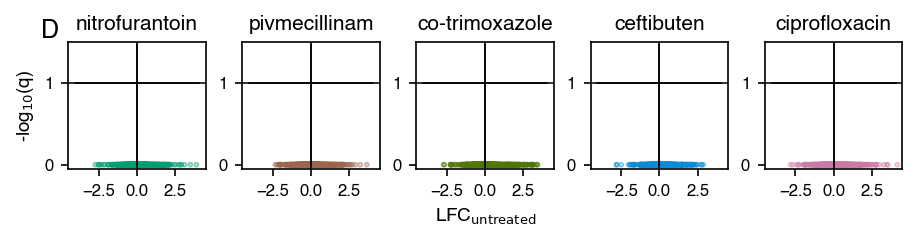

In [31]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 1.5))
def _plot_ancom_strip(fig):
    """
    Helper function for DA
    """
    gst = fig.add_gridspec(1, 5)
    for i in np.arange(1, 6):
        if i == 1:
            ax = fig.add_subplot(gst[i - 1])
        else:
            ax = fig.add_subplot(gst[i - 1], sharex=ax, sharey=ax)
    
        ax.scatter(x=baseline_ancombc.loc[baseline_ancombc[f'q_C(abx_code2){i}'] > 0.1, f'lfc_C(abx_code2){i}'],
                   y=-np.log10(baseline_ancombc.loc[baseline_ancombc[f'q_C(abx_code2){i}'] > 0.1, f'q_C(abx_code2){i}']),
                   marker='o',
                   s=3,
                   alpha=0.5,
                   color=colors[i],
                   facecolor='None',
                  )
        ax.scatter(x=baseline_ancombc.loc[baseline_ancombc[f'q_C(abx_code2){i}'] <= 0.1, f'lfc_C(abx_code2){i}'],
                   y=-np.log10(baseline_ancombc.loc[baseline_ancombc[f'q_C(abx_code2){i}'] <= 0.1, f'q_C(abx_code2){i}']),
                   marker='o',
                   s=3,
                   alpha=0.5,
                   color=colors[i],
                  )
        ax.set_xlabel('LFC$_{\\mathrm{untreated}}$', size=9)
        ax.set_ylabel('-log$_{10}$(q)', size=9)
        ax.set_title(abx_order[i], size=10)
        ax.yaxis.get_label().set_visible(i == 1)
        ax.xaxis.get_label().set_visible(i == 3)
        ax.xaxis.set_tick_params(labelsize=8)
        ax.yaxis.set_tick_params(labelsize=8)
    
    xlim = np.max(np.absolute(ax.get_xlim())) * np.array([-1, 1])
    ax.set_xlim(xlim)
    for ax in fig.axes:
        ax.plot([0, 0], [0, 1.5], 'k-', linewidth=0.75)
        ax.plot(xlim * 0.9, [1, 1], 'k-', linewidth=0.75)
    xlim = np.max(np.absolute(ax.get_xlim())) * np.array([-1, 1])
    ax.set_xlim(xlim)
    for ax in fig.axes:
        ax.plot([0, 0], [-0.05, 1.5], 'k-', linewidth=0.75)
        ax.plot(xlim, [1, 1], 'k-', linewidth=0.75)
        ax.set_ylim(-0.05, 1.5)
    
    fig.axes[0].text(xlim[0] - np.diff(xlim) * 0.2, 1.5, 'D', 
                     size=12, ha='left', va='bottom')
_plot_ancom_strip(fig)

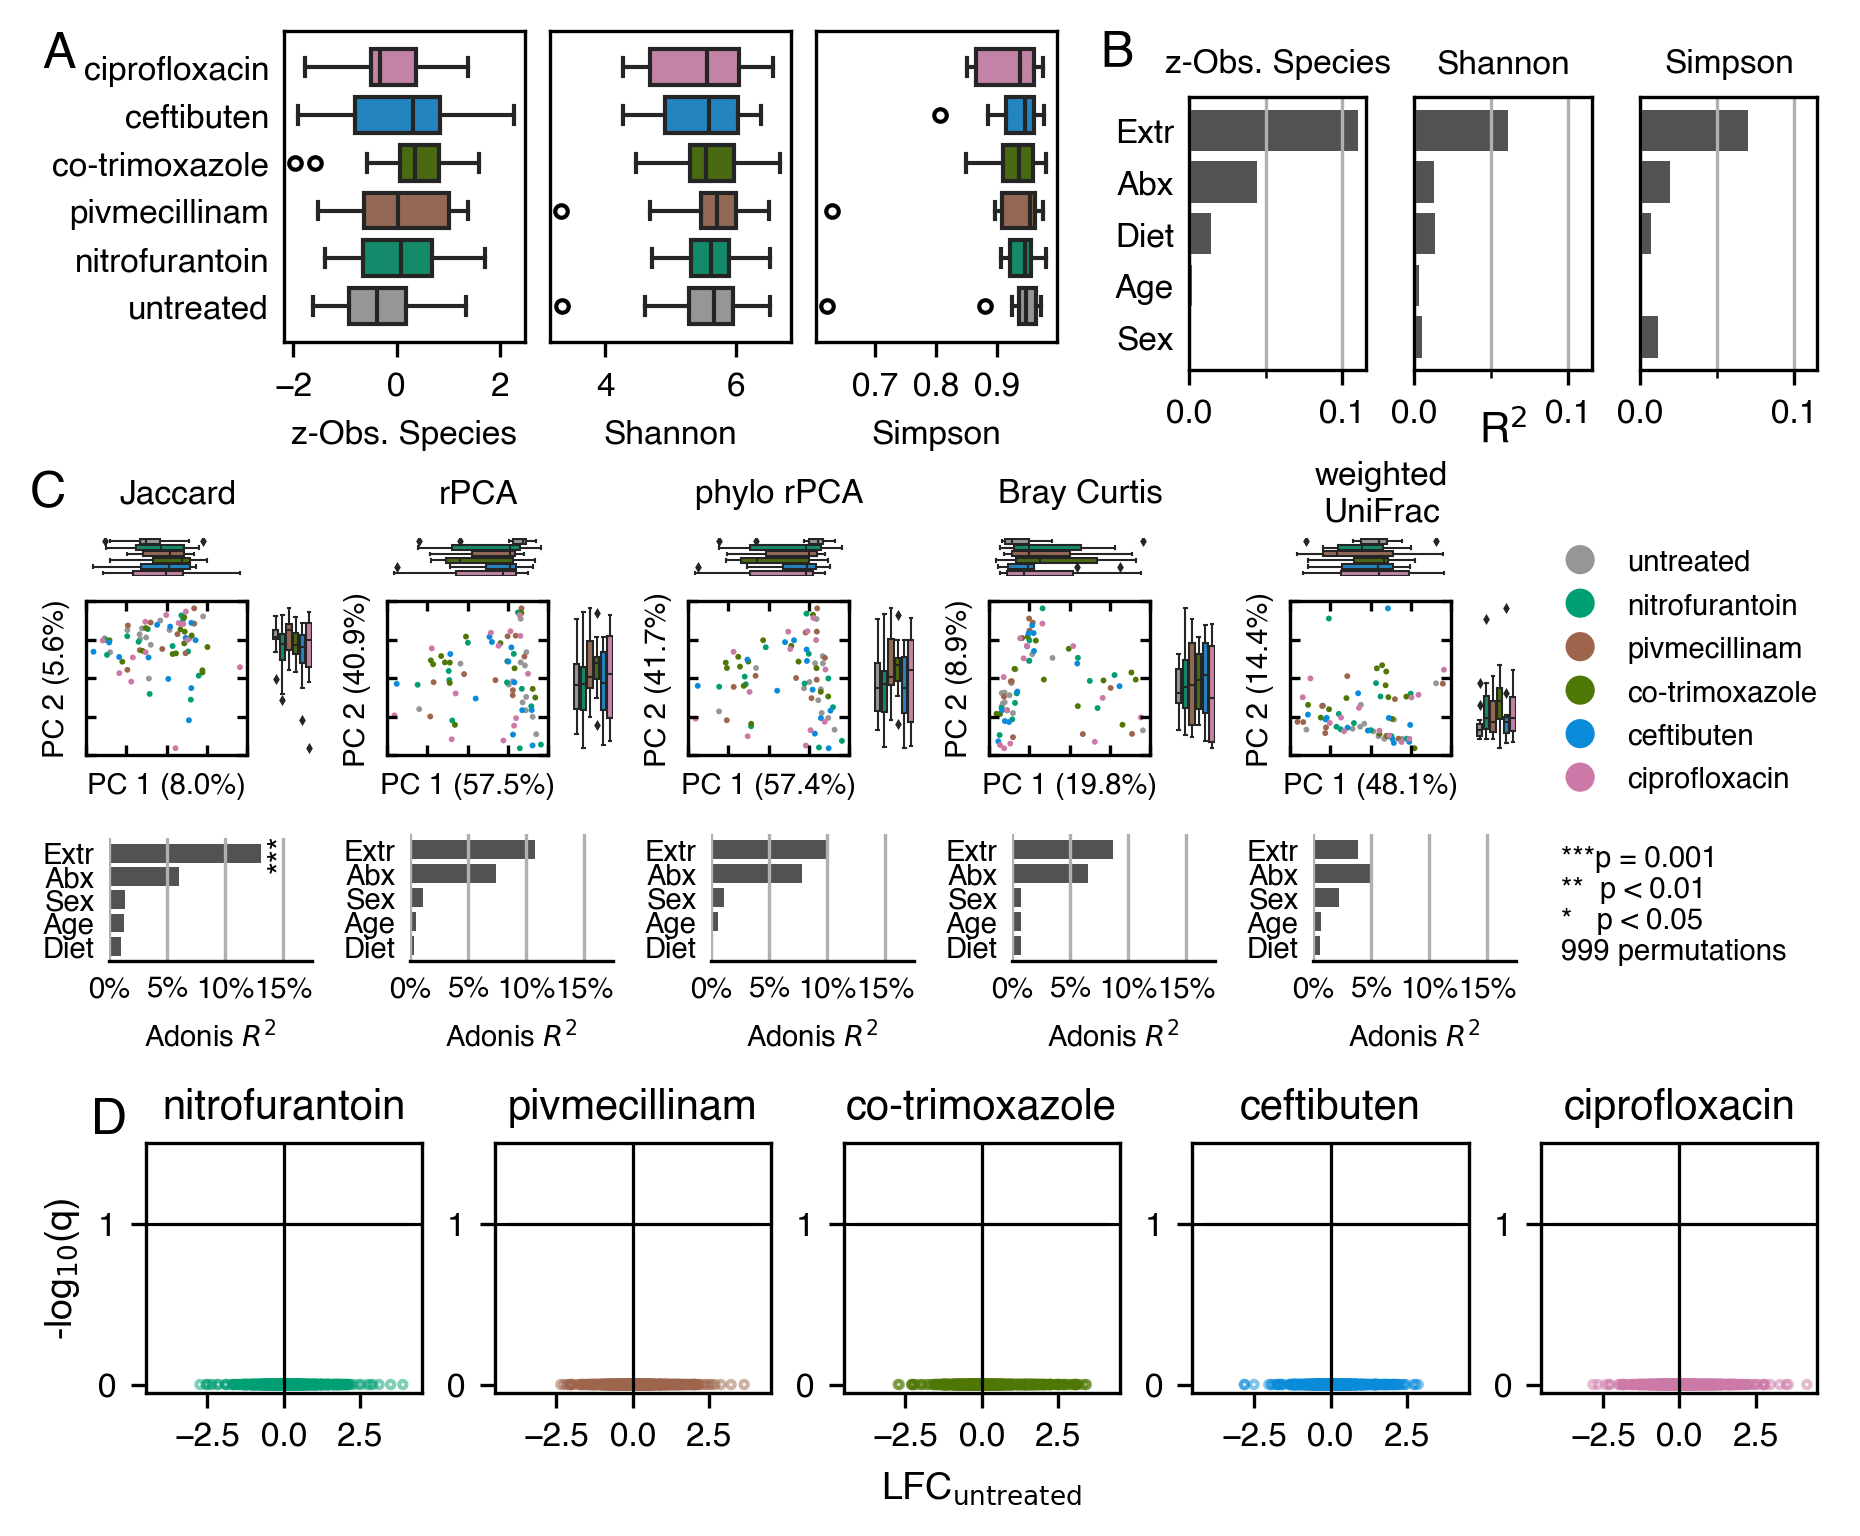

In [32]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(6, 5), facecolor='None')
[figa, figb, figda] = fig.subfigures(3, 1, height_ratios=[1.5, 2, 1.5], facecolor='None')
figaa, figab = figa.subfigures(1, 2, width_ratios=[3.5, 2.5], facecolor='None')
_plot_alpha_boxplot(figaa)
_plot_r2_alpha(figab)
_build_beta_panels(figb)
_plot_ancom_strip(figda)

**Figure S2. Taxonomic microbiome composition at baseline.** There is no difference in alpha diversity (A,B) between treatment allocation groups at baseline. (A) Boxplots show the distribution of (left to right) z-normalized Observed Species, Shannon Diversity, and Simpson Diversity. (B) Variance explained by alpha diversity at baseline by extraction plate (Extr), treatment allocation (abx), vegetarian diet (diet), participant age, and participant sex. No difference was statically significant. (C) There were no differences in beta diveristy at baseline between treatment groups. The top row shows ordiation projections colored by treatment group for (left to right) Jaccard distance, unweighted UniFrac distance, phylogenetic rPCA, Bray Curtis dissimilarity, and weighted UniFrac distance. The bottom row shoes the variance explained at baseline by extraction plate (Extr), treatment allocation (abx), vegetarian diet (diet), participant age, and participant sex. Variance as calculated with an adonis model with the variable of interest last; adonis was run with 999 permutations. (D) Volcano plot of ANCOM-BC based differential abundance at baseline. The horizonal line indicates an FDR corrected p-value of 0.1.

